# Overview

In [1]:
import warnings, logging
# pgmpy 1.1.x emits this FutureWarning from its own internal imports; it does not affect this notebook
warnings.filterwarnings('ignore', message='.*StructureScore.*', category=FutureWarning)
# pgmpy logs a warning whenever probabilities differ from 1 by floating-point rounding (~1e-16)
# and then corrects them itself; silence that noise
logging.getLogger('pgmpy').setLevel(logging.ERROR)

import nltk
from nltk import ngrams
from nltk.corpus import brown
from collections import defaultdict, Counter
import random
import pandas as pd
# pgmpy >= 1.0: discrete networks are DiscreteBayesianNetwork, and fit() takes an
# initialised estimator from pgmpy.parameter_estimator
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.parameter_estimator import DiscreteMLE
from pgmpy.sampling import BayesianModelSampling
from pgmpy.inference import VariableElimination, ApproxInference
from IPython.display import Image
from pgmpy.factors.discrete import State
from pgmpy.readwrite import BIFWriter
import time
import numpy as np
from pgmpy.utils.mathext import sample_discrete
import copy

np.random.seed(5149)  # reproducible samples

## Building an Ngram Language Model

An N-gram language model is a probabilistic model used in natural language processing (NLP) to predict the next word in a sequence based on the previous N-1 words. N-grams represent contiguous sequences of words or tokens of length N from a given text or corpus. These models are widely used in speech recognition, machine translation, and text prediction tasks.

#### How N-gram Language Models Work:
An N-gram model approximates the probability of a word based on the preceding n-1 words using the Markov assumption, which simplifies the computation by assuming that the next word depends only on the previous N-1 words, rather than the entire history.

The probability of a sentence $\mathbf{x} = [w_1, ..., w_m]$ is computed as: 

$P(w_1, ..., w_m) = \prod_{i=1}^{m} P(w_i \mid w_{i-N+1}, ..., w_{i-1})$

#### Types of N-grams:
* Unigram (N=1): The probability of each word is independent of any previous words. The probability of an individual word is computed as $P(w_i)$.
                    

Example:


Sequence: "The cat sat on the mat"

Unigrams: ["The", "cat", "sat", "on", "the", "mat"]

* Bigram (N=2): The probability of a word depends on the previous word. The probability is computed as $P(w_i | w_{i-1})$.
                            
                            
Example:

Sequence: "The cat sat on the mat"

Bigrams: ["The cat", "cat sat", "sat on", "on the", "the mat"]

* Trigram (N=3): The probability of a word depends on the two previous words. The corresponding probability is $P(w_i | w_{i-2}, w_{i-1})$.                          

Example:

Sequence: "The cat sat on the mat"

Trigrams: ["The cat sat", "cat sat on", "sat on the", "on the mat"]

* N-gram (General case): In general, an n-gram considers n-1 preceding words to predict the next word.


#### Learning Goals:
* Understand how a n-gram language model works.
* Apply and compare different inference methods for language models.

### 1. Data Preparation
We'll use the Brown corpus from the nltk library to build a ngram model. We make a Markov assumption that a word depends on at most two previous words.

In [2]:
# Load the Brown corpus, downloading it only if it is not already installed
try:
    brown.ensure_loaded()
except LookupError:
    nltk.download('brown')

# Load sentences from the 'news' category
brown_sentences = brown.sents(categories='news')

# Preprocess sentences: lowercase and add <START> and <END> tokens
processed_sentences = []
for sentence in brown_sentences:
    sentence = ['<START>'] + [word.lower() for word in sentence] + ['<END>']
    processed_sentences.append(sentence)


In [3]:
def create_ngram_dataset(processed_sentences, order = 3, threshold = 3):
    ngram_counts = Counter()
    for sentence in processed_sentences:
        ngram_counts.update(ngrams(sentence, order))
    # Keep n-grams that occur at least `threshold` times, with ONE ROW PER OCCURRENCE,
    # so that maximum likelihood estimation sees the true counts C(w1, w2, w3).
    ngram_data = []
    for ngram, count in ngram_counts.items():
        if count >= threshold:
            ngram_data.extend([ngram] * count)
    column_names = [f'word_{i}' for i in range(1, order+1)]
    df = pd.DataFrame(ngram_data, columns=column_names)
    return df

In [4]:
trigram_dataset = create_ngram_dataset(processed_sentences)

#### Explore the trigram dataset.

In [5]:
trigram_dataset.shape

(9505, 3)

In [6]:
trigram_dataset.head()

,word_1,word_2,word_3
0,the,fulton,county
1,the,fulton,county
2,the,fulton,county
3,an,investigation,of
4,an,investigation,of


### 2 Build a Bayesian network for the language model.

In [7]:
def visualize(bayesianNet, file_name = 'language model'):
    viz = bayesianNet.to_graphviz()
    viz.draw('%s.png' % file_name, prog='dot')
    return Image('%s.png' % file_name)

#### 2.1 Build a Bayesian network by making a Markov assumption that a word depends only on two preceding words.

In [8]:
edges = [('word_1','word_2'), ('word_1','word_3'), ('word_2','word_3')]
trigram_bigram_model = DiscreteBayesianNetwork(edges)

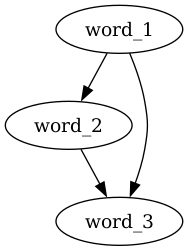

In [9]:
visualize(trigram_bigram_model, 'Trigram_Bigram_BN')

#### 2.2 Discuss the Pros and Cons of different possible designs. 

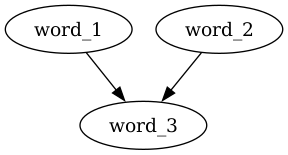

In [10]:
visualize(DiscreteBayesianNetwork([ ('word_1','word_3'), ('word_2','word_3')]), 'Trigram_BN')

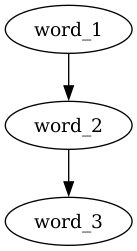

In [11]:
visualize(DiscreteBayesianNetwork([ ('word_1','word_2'), ('word_2','word_3')]), 'Linear-Chain_BN')

**Discussion.**

* **Full trigram network** ($w_1 \to w_2$, $w_1 \to w_3$, $w_2 \to w_3$): $P(w_1, w_2, w_3) = P(w_1) P(w_2 \mid w_1) P(w_3 \mid w_1, w_2)$ is the chain rule with no independence assumption inside the window, so it represents any distribution over trigrams and gives the bigram model $P(w_2 \mid w_1)$ for free. The cost is the trigram CPD, which has one column for every pair $(w_1, w_2)$: about 442 × 542 × 507 ≈ 121 million entries, almost all for contexts never seen in the data.
* **V-structure** ($w_1 \to w_3 \leftarrow w_2$): the same large CPD for $w_3$, but it also asserts that $w_1$ and $w_2$ are marginally independent, which is clearly false for consecutive words. It has no bigram CPD to back off to.
* **Linear chain** ($w_1 \to w_2 \to w_3$): a bigram model. Its CPDs are small (e.g. $P(w_3 \mid w_2)$ has about 442 × 507 entries) and much better estimated from sparse data, but it asserts $w_3 \perp w_1 \mid w_2$ and so loses the trigram context.

### 3. Training and Inference

#### 3.1 Train your language model on the trigram dataset.

In [12]:
# pgmpy >= 1.0: pass an initialised estimator. fit() updates the model in place (and also returns it).
trigram_bigram_model.fit(trigram_dataset, estimator=DiscreteMLE());

#### 3.2 Sample 10 trigrams from your model, which start with $<START>$.

In [13]:
ngram_sampler = BayesianModelSampling(trigram_bigram_model)

In [14]:
initial_tokens_ngrams = ngram_sampler.rejection_sample(size=10, evidence= [State(var='word_1', state='<START>')], show_progress=False)
initial_tokens_ngrams

,word_1,word_2,word_3
0,<START>,at,the
1,<START>,--,the
2,<START>,the,united
3,<START>,however,","
4,<START>,the,new
5,<START>,``,we
6,<START>,they,also
7,<START>,the,belgians
8,<START>,the,fact
9,<START>,they,will


#### 3.3  What is the most probable next word after [$<START>$, 'this', 'is']? (Under the trigram model, only the last two words, 'this is', matter.)

In [15]:
inf_ve = VariableElimination(trigram_bigram_model)
start_time = time.time()
# Evidence is on both parents of word_3, so the posterior is just one column of its CPD.
posterior = inf_ve.query(variables=['word_3'], evidence={'word_1': 'this', 'word_2': 'is'}, show_progress=False)
next_word = posterior.state_names['word_3'][int(np.argmax(posterior.values))]
print({'word_3': next_word})
print({s: round(float(p), 3) for s, p in zip(posterior.state_names['word_3'], posterior.values) if p > 0})
end_time = time.time()
elapsed_time = end_time - start_time
print(f"Running time: {elapsed_time:.6f} seconds")

# inf_ve.map_query(variables=['word_3'], evidence={'word_1': 'this', 'word_2': 'is'}) gives the same answer,
# but in pgmpy 1.1.x it runs classic variable elimination, which copies the 121-million-entry trigram CPD:
# about 10 seconds and roughly 5 GB of RAM on top of the model. query() uses tensor contraction on views.

{'word_3': 'a'}
{'a': 0.526, 'not': 0.211, 'the': 0.263}
Running time: 0.003429 seconds


Try it again with [$<START>$, 'the', 'award'], what do you observe?

In [16]:
try:
    inf_ve.query(variables=['word_3'], evidence={'word_1': 'the', 'word_2': 'award'}, show_progress=False)
except Exception as e:
    print(type(e).__name__, str(e)[:120], '...')
print("'award' is a state of word_2:", 'award' in trigram_bigram_model.get_cpds('word_2').state_names['word_2'])
print("'award' is a state of word_3:", 'award' in trigram_bigram_model.get_cpds('word_3').state_names['word_3'])

KeyError 'state: award is an unknown for variable: word_2. It must be one of [\'!\', \'&\', "\'\'", \'(\', \')\', \',\', \'--\',  ...
'award' is a state of word_2: False
'award' is a state of word_3: True


The query raises a `KeyError`. Each variable has its own state space, learnt from its own column of the data: "award" occurs as the third word of a kept trigram (we even sampled "<START> the award" above), but never as the second word, so it is not a valid value of `word_2`.

Even when both words are known states, a pair $(w_1, w_2)$ that never occurs in the data has no counts, and pgmpy fills that column of $P(w_3 \mid w_1, w_2)$ with a uniform distribution, so the "most probable" next word would be arbitrary. This sparsity is what Katz back-off (Section 3.5) addresses.

Inspect the sizes of the CPDs. Why can exact inference with this network be slow and memory-hungry?

In [17]:
ngram_cpds = trigram_bigram_model.get_cpds()
for cpd in ngram_cpds:
    print(cpd.variable, np.array(cpd.get_values()).shape)
print('observed (w1, w2) contexts:', len(set(zip(trigram_dataset['word_1'], trigram_dataset['word_2']))))

word_1 (542, 1)
word_2 (507, 542)


word_3 (442, 274794)
observed (w1, w2) contexts: 1275


The trigram CPD $P(w_3 \mid w_1, w_2)$ has a column for every pair $(w_1, w_2)$ of known words: 442 rows × 274,794 columns ≈ 121 million probabilities (≈ 1 GB as 64-bit floats), although only the 1,275 contexts observed in the data carry any information. Fitting it, copying it (the sampler keeps its own copy) and running variable elimination over it are all slow and memory-hungry. Here `query` is fast only because the evidence covers both parents of `word_3`, so the answer is a single column of the CPD; `map_query` runs classic variable elimination, which builds full copies of this factor.

#### 3.4 Sample the next word for each of the trigrams you sampled.

print the new ngram extended with the sampled word with print(' '.join(ngram))

In [18]:
# Rejection sampling accepts a forward sample only if it matches the evidence, so the acceptance
# probability is P(word_1 = a, word_2 = b) = P(a) P(b | a). If it is 0, rejection sampling never finishes.
unigram_cpd = trigram_bigram_model.get_cpds('word_1')
bigram_cpd = trigram_bigram_model.get_cpds('word_2')

def evidence_prob(word_1, word_2):
    if word_1 not in unigram_cpd.name_to_no['word_1'] or word_2 not in bigram_cpd.name_to_no['word_2']:
        return 0.0
    return unigram_cpd.get_value(word_1=word_1) * bigram_cpd.get_value(word_1=word_1, word_2=word_2)

for row in initial_tokens_ngrams.itertuples():
    sentence = [row.word_1, row.word_2, row.word_3]
    p_accept = evidence_prob(row.word_2, row.word_3)
    if p_accept == 0:
        print(' '.join(sentence), '-> skipped: P(evidence) = 0, rejection sampling would never finish')
        continue
    start_time = time.time()
    new_trigram = ngram_sampler.rejection_sample(size=1, evidence= [State(var='word_1', state=row.word_2), State(var='word_2', state=row.word_3)], show_progress=False)
    sentence.append(new_trigram.iloc[0].word_3)
    elapsed_time = time.time() - start_time
    print(' '.join(sentence), f'| P(evidence) = {p_accept:.1e}, ~{1/p_accept:,.0f} forward samples per accepted one, {elapsed_time:.2f} s')

print(f"\nFor comparison, P(word_1 = <START>) = {unigram_cpd.get_value(word_1='<START>'):.3f}")

<START> at the university | P(evidence) = 3.5e-03, ~288 forward samples per accepted one, 0.20 s
<START> -- the -> skipped: P(evidence) = 0, rejection sampling would never finish
<START> the united states | P(evidence) = 4.6e-03, ~216 forward samples per accepted one, 0.06 s
<START> however , that | P(evidence) = 1.4e-03, ~731 forward samples per accepted one, 0.06 s
<START> the new york | P(evidence) = 1.8e-03, ~559 forward samples per accepted one, 0.06 s


<START> `` we must | P(evidence) = 1.1e-03, ~950 forward samples per accepted one, 0.06 s
<START> they also -> skipped: P(evidence) = 0, rejection sampling would never finish


<START> the belgians , | P(evidence) = 3.2e-04, ~3,168 forward samples per accepted one, 0.36 s
<START> the fact that | P(evidence) = 1.2e-03, ~864 forward samples per accepted one, 0.14 s


<START> they will be | P(evidence) = 5.3e-04, ~1,901 forward samples per accepted one, 0.50 s

For comparison, P(word_1 = <START>) = 0.120


Why can the sampling algorithm you chose be slow, or never finish, for some trigrams? Why does it work well when sampling the trigrams beginning with $<START>$?

Rejection sampling draws complete samples $(w_1, w_2, w_3)$ from the network and throws away those that do not match the evidence, so the probability of accepting a sample is $P(w_1 = a, w_2 = b) = P(a)\,P(b \mid a)$. With two observed words this is tiny (around $10^{-4}$ here), so thousands of forward samples are wasted per accepted one; if the pair $(a, b)$ never occurs in the training data it is exactly 0 and rejection sampling never finishes (this is why the original version of this cell had to be interrupted). With only $w_1 = <START>$ observed, the acceptance probability is $P(<START>) \approx 0.11$, so about one sample in nine is accepted.

Because the evidence variables are the parents of `word_3`, rejection is unnecessary: we can sample $w_3$ directly from the reduced CPD $P(w_3 \mid w_1 = a, w_2 = b)$, which is what Section 3.5 does.

#### 3.5 Katz Back-off Smoothing for N-gram Language Models
Katz back-off is a smoothing technique used in N-gram language models to address the problem of data sparsity. When an N-gram (a sequence of N words) is not present in the training data, Katz back-off assigns a probability to that N-gram by backing off to a lower-order N-gram model (e.g., a bigram or unigram) while applying discounting to reallocate some probability mass from higher-order N-grams to lower-order ones.

$
P_{\text{Katz}}(w_i \mid w_{i-2}, w_{i-1}) =
\begin{cases} 
    \frac{C(w_{i-2}, w_{i-1}, w_i)}{C(w_{i-2}, w_{i-1})}, & \text{if } C(w_{i-2}, w_{i-1}, w_i) > 0 \\
    \alpha(w_{i-2}, w_{i-1}) P_{\text{Katz}}(w_i \mid w_{i-1}), & \text{if } C(w_{i-2}, w_{i-1}, w_i) = 0
\end{cases}
$

C() is the function to count the frequency of an n-gram. $\alpha(w_{i-2}, w_{i-1})$ is a hyperparameter, we assume it is 1 in this applied session.

Example of Katz Back-off

Consider a trigram model trained on the sentence: "the cat sat on the mat". Now, let’s say we want the probability that "sat" follows "the cat".

Step 1: Check if the trigram "the cat sat" exists in the training data.

If it exists, we calculate $𝑃("sat"∣"the", "cat") = \frac{𝐶("the\hspace{1pt} cat \hspace{1pt} sat")}{𝐶("the \hspace{1pt}cat")}$ otherwise $P("sat"∣"cat")= \frac{C("cat\hspace{1pt} sat")}{C("cat")}$.

Step 2: If the bigram "cat sat" also has zero counts, we further back off to the unigram model and estimate $𝑃("sat")$.

**Sampling with back-off.** With $\alpha = 1$ and no discounting, $P_{\text{Katz}}$ above is not a normalised distribution, so we cannot sample from it directly. In this applied session we use the common simplification of backing off on the *context*: if the context $(w_{i-2}, w_{i-1})$ was observed in the training data, sample $w_i$ from $P(w_i \mid w_{i-2}, w_{i-1})$; otherwise sample from $P(w_i \mid w_{i-1})$; and if $w_{i-1}$ was never observed either, sample from $P(w_i)$.

Note that checking whether the two words are *known states* of the CPD is not enough: for a parent configuration with no data, maximum likelihood estimation has nothing to normalise, and pgmpy fills that column with a uniform distribution over all values of $w_i$.

Use the following methods to implement a method to sample a sentence. It stops either a prespecfied maximal length is reached or a $<END>$ is generated.

In [19]:
# Select CPDs by variable name rather than by position in get_cpds()

trigram_cpd = trigram_bigram_model.get_cpds('word_3') # P(w3 | w1, w2)
bigram_cpd = trigram_bigram_model.get_cpds('word_2') # P(w2 | w1)
unigram_cpd = trigram_bigram_model.get_cpds('word_1') # P(w1)

Modify the following code using the correct trigram CPD to sample the next word of "this is".

In [20]:
# Reduce the factor of the CPD with the given evidence.
reduced_cpd = trigram_cpd.reduce([('word_1','this'), ('word_2','is')], inplace=False)
np.array(reduced_cpd.get_values()).shape

(442, 1)

In [21]:
# Sample from the reduced factor using sample_discrete
reduced_states = np.array(reduced_cpd.state_names['word_3'])
reduced_probs = np.array(reduced_cpd.get_values()).reshape(-1)
str(sample_discrete(reduced_states, reduced_probs)[0])

'not'

In [22]:
# Contexts (w1, w2) that actually occur in the training data. Back off whenever the
# context is unseen: pgmpy fills CPD columns for unseen parent configurations with a
# uniform distribution, so the CPD alone cannot tell us that a context had no data.
trigram_contexts = set(zip(trigram_dataset['word_1'], trigram_dataset['word_2']))
len(trigram_contexts)

1275

In [23]:
# Sample the next word from P(w3 | w1, w2); return '' if the context (w1, w2) was never observed.
def sample_next_trigram(trigram_cpd, word_1, word_2):
    if (word_1, word_2) in trigram_contexts:
        reduced_cpd = trigram_cpd.reduce([('word_1',word_1), ('word_2',word_2)], inplace=False)
        reduced_states = np.array(reduced_cpd.state_names['word_3'])
        reduced_probs = np.array(reduced_cpd.get_values()).reshape(-1)
        next_word = sample_discrete(reduced_states, reduced_probs)[0]
        return next_word
    return ''

In [24]:
# Sample the next word from P(w2 | w1); return '' if w1 was never observed.
def sample_next_bigram(bigram_cpd, word_1):
    if word_1 in bigram_cpd.name_to_no['word_1']:
        reduced_cpd = bigram_cpd.reduce([('word_1',word_1)], inplace=False)
        reduced_states = np.array(reduced_cpd.state_names['word_2'])
        reduced_probs = np.array(reduced_cpd.get_values()).reshape(-1)
        next_word = sample_discrete(reduced_states, reduced_probs)[0]
        return next_word
    return ''

In [25]:
def sample_next_unigram(unigram_cpd):
    df_unigram = unigram_cpd.sample(1)
    return df_unigram['word_1'].iloc[0]

#### Implement the Katz back-off smoothing to sample sentences using the methods above.

In [26]:
def sample_sentences(sampler, n_sentences, max_length):
    initial_tokens = sampler.rejection_sample(size=n_sentences, evidence= [State(var='word_1', state='<START>')], show_progress=False)
    partial_sentences = []
    complete_sentences = []

    for row in initial_tokens.itertuples():
        sentence = [row.word_1, row.word_2, row.word_3]
        if row.word_2 != '<END>':
            if  row.word_3 == '<END>':
                complete_sentences.append(sentence)
            else:
                partial_sentences.append(sentence)

    for partial_sentence in partial_sentences:
        while len(partial_sentence) < max_length:
            next_word = sample_next_trigram(trigram_cpd, partial_sentence[-2], partial_sentence[-1])
            if next_word == '':
                next_word = sample_next_bigram(bigram_cpd, partial_sentence[-1])
                if next_word == '':
                    next_word = sample_next_unigram(unigram_cpd)
            if next_word == '<END>':
                partial_sentence.append(next_word)
                break
            if next_word != '<START>':
                partial_sentence.append(next_word)

        # sentences that reach max_length without <END> are discarded
        if partial_sentence[-1] == '<END>':
            complete_sentences.append(partial_sentence)

    return complete_sentences

In [27]:
sens_set = sample_sentences(ngram_sampler, 20, 25)  # news sentences average ~20 words
for sens in sens_set:
    print(' '.join(sens))

<START> he called dolce vita '' and `` but i who has been no reason to believe that the board of education . <END>
<START> mr. hawksley said he was the first day of the country . <END>
<START> now , will be held in the early in the congo , mrs. robert o. spurdle the son of the `` family . <END>
<START> mr. hawksley said he would be given the day . <END>
<START> the british and french '' . <END>
<START> at the same time , the statement last year . <END>
<START> but the views of the problem of each month . <END>
<START> from the university of oklahoma trial . <END>
<START> but the b & attack . <END>
<START> she was able to be an hour , is a result , it is a week . <END>
<START> she was in the state . <END>
<START> he was not to be a special session . <END>
<START> the department of the university of oklahoma of the white house . <END>
<START> in addition to the congo . <END>
<START> when the teamsters union . <END>
<START> there was a member of the u.s. . <END>
<START> `` but i of the am

### 4. Demo: Gibbs Sampling for N-grams.

Goal: improve an existing n-gram using Gibbs sampling.

Gibbs sampling repeatedly resamples one word $w_i$ from its full conditional given all other words. Under a trigram model, $w_i$ appears in exactly three factors, so

$P(w_i \mid \text{all other words}) \propto P(w_i \mid w_{i-2}, w_{i-1}) \, P(w_{i+1} \mid w_{i-1}, w_i) \, P(w_{i+2} \mid w_i, w_{i+1})$,

i.e. only the Markov blanket $w_{i-2}, w_{i-1}, w_{i+1}, w_{i+2}$ matters. Each factor is scored with the back-off model from Section 3.5, so the same model generates and refines sentences. $<START>$ and $<END>$ are never resampled.

In [28]:
# Probability of the word at position j given its history, using the back-off model of Section 3.5.
# sentence[0] is <START>, so j = 1 uses the bigram CPD P(w_1 | <START>).
def ngram_prob(sentence, j):
    w3, w2 = sentence[j], sentence[j-1]
    w1 = sentence[j-2] if j >= 2 else None
    if w1 is not None and (w1, w2) in trigram_contexts:
        if w3 in trigram_cpd.name_to_no['word_3']:
            return trigram_cpd.get_value(word_1=w1, word_2=w2, word_3=w3)
        return 0.0
    if w2 in bigram_cpd.name_to_no['word_1']:
        if w3 in bigram_cpd.name_to_no['word_2']:
            return bigram_cpd.get_value(word_1=w2, word_2=w3)
        return 0.0
    if w3 in unigram_cpd.name_to_no['word_1']:
        return unigram_cpd.get_value(word_1=w3)
    return 0.0

In [29]:
# Gibbs step: resample the word at position i (0 < i < len(sentence) - 1) from its full conditional.
candidate_words = [w for w in trigram_cpd.state_names['word_3'] if w not in ('<START>', '<END>')]

def resample_word(sentence, i):
    weights = []
    for word in candidate_words:
        proposal = sentence[:i] + [word] + sentence[i+1:]
        p = 1.0
        # the three factors that contain position i: positions i, i+1, i+2
        for j in range(i, min(i + 3, len(sentence))):
            p *= ngram_prob(proposal, j)
            if p == 0:
                break
        weights.append(p)
    weights = np.array(weights)
    if weights.sum() == 0:
        return  # no candidate is consistent with the neighbours; keep the current word
    next_word = sample_discrete(np.array(candidate_words), weights / weights.sum())[0]
    if sentence[i] != next_word:
        sentence[i] = next_word
        print('replace a word at {0}: {1}'.format(i, ' '.join(sentence)))

In [30]:
# Apply Gibbs sampling to resample an ngram.
def gibbs_sample(sens, n_iterations = 10):
    print('improve {0}'.format(' '.join(sens)))
    sentence = copy.deepcopy(sens)
    for t in range(n_iterations):
        for index in range(1, len(sentence) - 1):
            resample_word(sentence, index)
    return sentence

In [31]:
' '.join(gibbs_sample(max(sens_set, key=len)))  # improve the longest sampled sentence

improve <START> now , will be held in the early in the congo , mrs. robert o. spurdle the son of the `` family . <END>
replace a word at 1: <START> but , will be held in the early in the congo , mrs. robert o. spurdle the son of the `` family . <END>
replace a word at 2: <START> but they will be held in the early in the congo , mrs. robert o. spurdle the son of the `` family . <END>
replace a word at 11: <START> but they will be held in the early in the house , mrs. robert o. spurdle the son of the `` family . <END>
replace a word at 17: <START> but they will be held in the early in the house , mrs. robert o. spurdle , son of the `` family . <END>
replace a word at 18: <START> but they will be held in the early in the house , mrs. robert o. spurdle , president of the `` family . <END>
replace a word at 11: <START> but they will be held in the early in the past , mrs. robert o. spurdle , president of the `` family . <END>
replace a word at 18: <START> but they will be held in the early 

'<START> if they will be held in the early in the five , mrs. robert o. spurdle as one of the `` family . <END>'